In [26]:
import requests

url = "https://zenodo.org/records/6849907/files/kpets_400.zip?download=1"

response = requests.get(url)
response.raise_for_status()

with open("/content/kpets_400.zip", "wb") as f:
    f.write(response.content)

print("Download completed!")

Download completed!


In [27]:
import zipfile
import os

zip_path = "/content/kpets_400.zip"
extract_path = "/content/cats_dogs_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

Extraction completed!


In [28]:
cat_path = None
dog_path = None

for root, dirs, files in os.walk(extract_path):
    for folder in dirs:
        if folder.lower() == "cats":
            cat_path = os.path.join(root, folder)

        elif folder.lower() == "dogs":
            dog_path = os.path.join(root, folder)

print("Cat folder:", cat_path)

Cat folder: /content/cats_dogs_dataset/kpets_400/cats


In [29]:
for root, dirs, files in os.walk(extract_path):
    print(root, ":", len(files), "files")

/content/cats_dogs_dataset : 0 files
/content/cats_dogs_dataset/kpets_400 : 0 files
/content/cats_dogs_dataset/kpets_400/cats : 0 files
/content/cats_dogs_dataset/kpets_400/cats/images : 191 files
/content/cats_dogs_dataset/kpets_400/cats/labels : 191 files
/content/cats_dogs_dataset/kpets_400/dogs : 0 files
/content/cats_dogs_dataset/kpets_400/dogs/images : 193 files
/content/cats_dogs_dataset/kpets_400/dogs/labels : 193 files


In [30]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

cat_images = []
dog_images = []

for root, dirs, files in os.walk(cat_path):
    for f in files:
        path = os.path.join(root, f)
        try:
            with Image.open(path) as img:
                img.verify()
            cat_images.append(path)
        except:
            pass

for root, dirs, files in os.walk(dog_path):
    for f in files:
        path = os.path.join(root, f)
        try:
            with Image.open(path) as img:
                img.verify()
            dog_images.append(path)
        except:
            pass

print("Cats:", len(cat_images))
print("Dogs:", len(dog_images))

Cats: 191
Dogs: 193


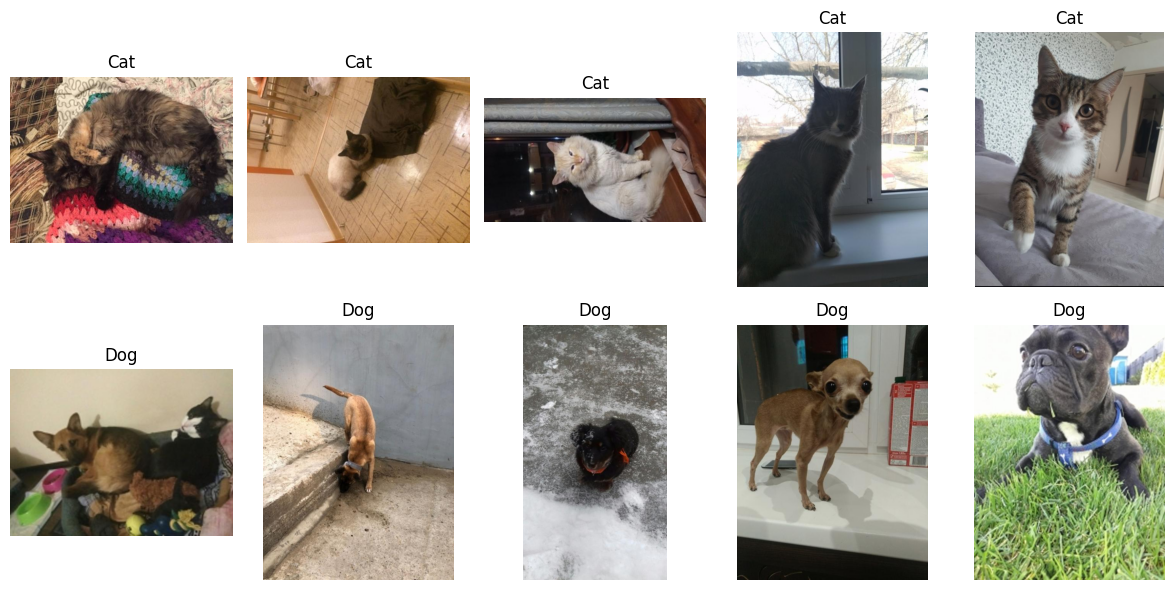

In [31]:
plt.figure(figsize=(12, 6))

for i, path in enumerate(random.sample(cat_images, 5)):
    img = Image.open(path).convert("RGB")
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title("Cat")
    plt.axis("off")

for i, path in enumerate(random.sample(dog_images, 5)):
    img = Image.open(path).convert("RGB")
    plt.subplot(2, 5, i + 6)
    plt.imshow(img)
    plt.title("Dog")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [32]:
cat_images = []
dog_images = []

for root, dirs, files in os.walk(cat_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            cat_images.append(os.path.join(root, file))

for root, dirs, files in os.walk(dog_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            dog_images.append(os.path.join(root, file))

print("Total Cats:", len(cat_images))
print("Total Dogs:", len(dog_images))
print("Total Images:", len(cat_images) + len(dog_images))

Total Cats: 191
Total Dogs: 193
Total Images: 384


In [33]:
from sklearn.model_selection import train_test_split

all_images = cat_images + dog_images

all_labels = (
    [0] * len(cat_images) +
    [1] * len(dog_images)
)

X_train, X_test, y_train, y_test = train_test_split(
    all_images,
    all_labels,
    test_size=0.20,
    random_state=42,
    stratify=all_labels
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 260
Validation images: 47
Testing images: 77


In [34]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [35]:
IMG_SIZE = 160
BATCH_SIZE = 16

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )

    return image, tf.cast(label, tf.float32)


def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            len(paths),
            seed=42
        )

    return dataset.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )


train_ds = create_dataset(X_train, y_train, True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

print("Preprocessing completed!")

Preprocessing completed!


In [36]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models


base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)


base_model.trainable = False

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])


model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),

    data_augmentation,

    layers.Rescaling(1./127.5, offset=-1),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [37]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

Epoch 1/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 16s 558ms/step - accuracy: 0.6423 - loss: 0.6949 - val_accuracy: 0.7660 - val_loss: 0.4891
Epoch 2/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 463ms/step - accuracy: 0.7192 - loss: 0.5590 - val_accuracy: 0.8298 - val_loss: 0.3976
Epoch 3/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 495ms/step - accuracy: 0.7923 - loss: 0.4566 - val_accuracy: 0.8085 - val_loss: 0.3614
Epoch 4/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 398ms/step - accuracy: 0.8423 - loss: 0.3834 - val_accuracy: 0.8511 - val_loss: 0.3305
Epoch 5/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 10s 558ms/step - accuracy: 0.8538 - loss: 0.3393 - val_accuracy: 0.8298 - val_loss: 0.3228
Epoch 6/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 424ms/step - accuracy: 0.8538 - loss: 0.3435 - val_accuracy: 0.8511 - val_loss: 0.3221
Epoch 7/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 10s 423ms/step - accuracy: 0.8731 - loss: 0.3277 - val_accuracy: 0.8723 - val_loss: 0.3225
Epoch 8/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 508ms/step - accuracy: 0.8692 - loss: 0.3251 - val_accuracy:

In [44]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", round(test_loss, 4))

print(
    "MobileNetV2 Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 475ms/step - accuracy: 0.8442 - loss: 0.3411
Test Loss: 0.3411
MobileNetV2 Test Accuracy: 84.42 %


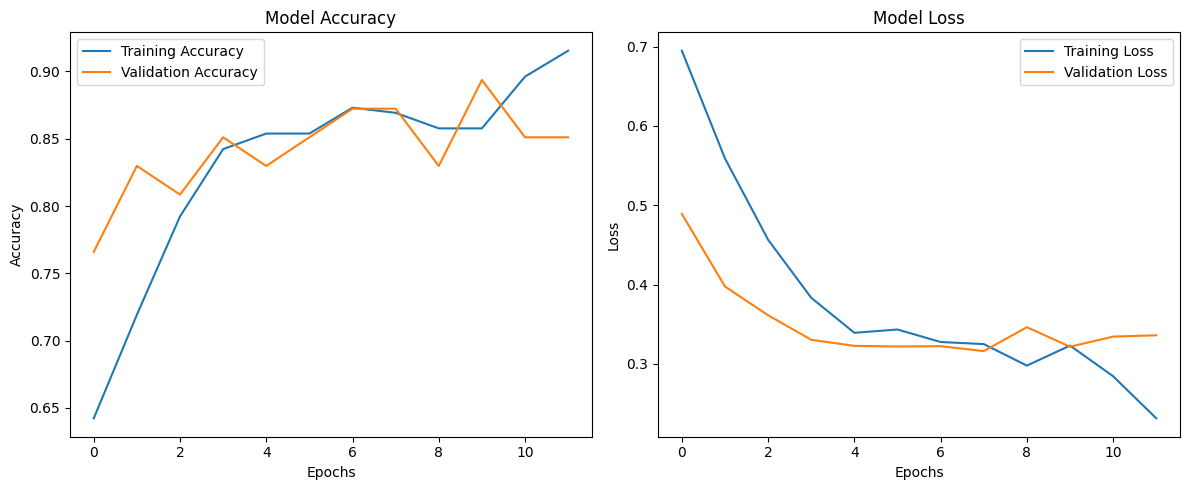

In [43]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [40]:
y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(images, verbose=0)

    y_pred.extend(
        (predictions.flatten() >= 0.5).astype(int)
    )

    y_true.extend(labels.numpy().astype(int))

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Cat", "Dog"]
))

              precision    recall  f1-score   support

         Cat       0.81      0.89      0.85        38
         Dog       0.89      0.79      0.84        39

    accuracy                           0.84        77
   macro avg       0.85      0.84      0.84        77
weighted avg       0.85      0.84      0.84        77



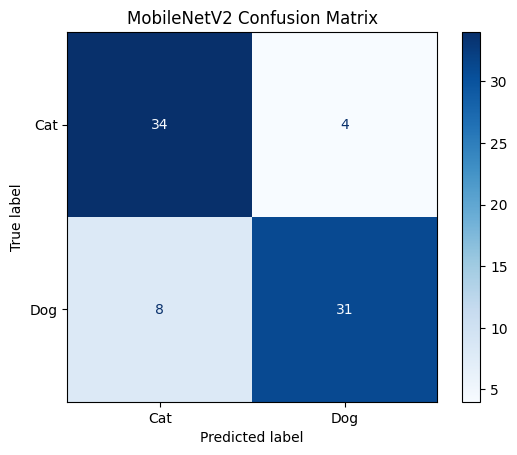

In [41]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

disp.plot(cmap="Blues")

plt.title("MobileNetV2 Confusion Matrix")
plt.show()

In [42]:
model.save("cats_dogs_mobilenetv2.keras")

print("Model saved successfully!")

Model saved successfully!
